# Notebook 13: All misclassified test images (recipe F)

Collects every test image that a fine-tuned model got wrong with recipe F in E1, E2 and E3 (0 to 3 per model), and draws them in one figure with the true class, and for each wrong model the predicted class and confidence. No GPU and no training; about 2 min.

**Inputs (Add Input -> Your Work):** Stage 0 output (`stage0/metadata/manifest.csv`, standardized images) and Notebook 2 output, final version (`results/all`, `results/single`, `results/multi`; reads `F/test_predictions.csv`).
**Outputs (`/kaggle/working/misclassified/`):** `misclassified_test_images.csv`, `res_misclassified.pdf/.png` (Times font, for the supplement or main text), and a zip.

In [1]:
import os, json, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path(os.environ.get("BD_INPUT", "/kaggle/input" if ON_KAGGLE else r"H:\BD Weapon Inputs"))
WORK = Path(os.environ.get("BD_WORK", "/kaggle/working" if ON_KAGGLE else r"H:\BD Weapon Analysis"))
OUT = WORK / "misclassified"; OUT.mkdir(parents=True, exist_ok=True)
INCLUDE_DINO = False            # True: also show DINOv2 + LR errors (it makes more)
NAME = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "convnext_tiny": "ConvNeXt-Tiny",
        "vit_small_patch16_224": "ViT-S/16"}
SCEN = {"all": "E1", "single": "E2", "multi": "E3"}

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)

rows = []
for sc in SCEN:
    res = walk_find(INPUT_ROOT, lambda d, f, sc=sc: d if ("summary_all.csv" in f and d.name == sc
                                                          and d.parent.name == "results") else None)
    if res is None:
        print("not found: results/" + sc); continue
    for mdir in sorted(p for p in res.iterdir() if p.is_dir()):
        f = mdir / "F" / "test_predictions.csv"
        if not f.exists():
            continue
        if mdir.name not in NAME and not (INCLUDE_DINO and "dino" in mdir.name):
            continue
        d = pd.read_csv(f, dtype={"image_id": str})
        pcols = [c for c in d.columns if c.startswith("p_")]
        d["conf"] = d[pcols].max(axis=1)
        d["p_true"] = d[pcols].to_numpy()[np.arange(len(d)), d.y.to_numpy()]
        d["model"], d["scenario"] = mdir.name, SCEN[sc]
        rows.append(d)
        print(f"{SCEN[sc]} {NAME.get(mdir.name, mdir.name):16s}: {int((d.y != d.pred).sum())} errors / {len(d)}")
allp = pd.concat(rows, ignore_index=True)
err = allp[allp.y != allp.pred].copy()
err["true"] = np.array(CLASSES)[err.y]; err["predicted"] = np.array(CLASSES)[err.pred]
err = err.merge(manifest[["image_id", "path", "label", "subset"]].rename(columns={"subset": "subset_m"}), on="image_id", how="left")
err[["scenario", "model", "image_id", "subset", "true", "predicted", "conf", "p_true", "path"]
    ].round(3).sort_values(["image_id", "scenario"]).to_csv(OUT / "misclassified_test_images.csv", index=False)
print(f"\n{len(err)} errors on {err.image_id.nunique()} distinct images")
display(err[["scenario", "model", "image_id", "subset", "true", "predicted", "conf"]].round(3))

E1 ConvNeXt-Tiny   : 1 errors / 419
E1 EfficientNet-B0 : 0 errors / 419
E1 ResNet-50       : 1 errors / 419
E1 ViT-S/16        : 0 errors / 419
E2 ConvNeXt-Tiny   : 1 errors / 255
E2 EfficientNet-B0 : 0 errors / 255
E2 ResNet-50       : 3 errors / 255
E2 ViT-S/16        : 1 errors / 255
E3 ConvNeXt-Tiny   : 0 errors / 164
E3 EfficientNet-B0 : 0 errors / 164
E3 ResNet-50       : 1 errors / 164
E3 ViT-S/16        : 0 errors / 164

8 errors on 4 distinct images


,scenario,model,image_id,subset,true,predicted,conf
0,E1,convnext_tiny,3b2b02d1c68a,single,Kodal,Dao,0.583
1,E1,resnet50,3b2b02d1c68a,single,Kodal,Dao,0.599
2,E2,convnext_tiny,cf6567946825,single,Churi,Kodal,0.454
3,E2,resnet50,cf6567946825,single,Churi,Kodal,0.255
4,E2,resnet50,3880e241521f,single,Kodal,Kural,0.569
5,E2,resnet50,3b2b02d1c68a,single,Kodal,Dao,0.377
6,E2,vit_small_patch16_224,cf6567946825,single,Churi,Kodal,0.264
7,E3,resnet50,86592ae7378d,multi,Kural,Shabol,0.663


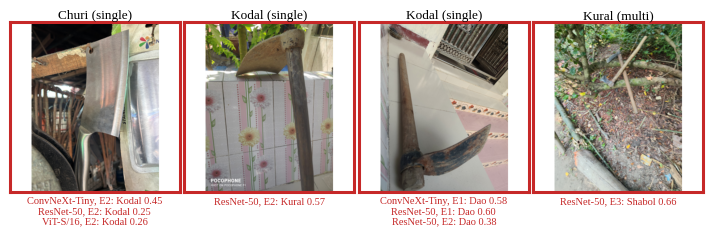

Done: /kaggle/working/misclassified.zip


In [2]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "pdf.fonttype": 42, "font.size": 9})
imgs = err.drop_duplicates("image_id").sort_values(["true", "image_id"]).reset_index(drop=True)
n = len(imgs); ncol = min(4, max(n, 1)); nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(1.75 * ncol + 0.2, 2.45 * nrow), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for k, r in imgs.iterrows():
    ax = axes.ravel()[k]
    im = ImageOps.pad(Image.open(STAGE0 / r.path).convert("RGB"), (300, 300), color=(255, 255, 255))
    ax.imshow(im); ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor("#C62828"); s.set_linewidth(2.2)
    ax.set_title(f"{r.true} ({r.subset})", fontsize=9.5, pad=3)
    lines = []
    for e in err[err.image_id == r.image_id].sort_values(["scenario", "model"]).itertuples():
        lines.append(f"{NAME.get(e.model, 'DINOv2')}, {e.scenario}: {e.predicted} {e.conf:.2f}")
    ax.set_xlabel("\n".join(lines), fontsize=7.5, color="#C62828", labelpad=3, linespacing=1.15)
fig.tight_layout(h_pad=0.6, w_pad=0.4)
for ext in ("pdf", "png"):
    fig.savefig(OUT / f"res_misclassified.{ext}", dpi=300, bbox_inches="tight")
plt.show()
with zipfile.ZipFile(WORK / "misclassified.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f"misclassified/{f.name}")
print("Done:", WORK / "misclassified.zip")